# Deep Q-Learning for Cart Pole (PyTorch)

In this notebook, we will use Deep Q-Learning to solve Cart Pole.


Environment: (https://gymnasium.farama.org/environments/classic_control/cart_pole/).

Paper: (https://arxiv.org/abs/1312.5602).

In [3]:
import random
from collections import deque, namedtuple

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"gymnasium {gym.__version__} | torch {torch.__version__} | device: {device}")
if device.type == "cuda":
    print(torch.cuda.get_device_name(0), f"| VRAM: {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")

gymnasium 1.4.0 | torch 2.14.1+cu130 | device: cuda
NVIDIA GeForce GTX 1650 | VRAM: 3.9 GB


In [4]:
# Sem Xvfb: o rgb_array do CartPole renderiza offscreen
env = gym.make("CartPole-v1", render_mode="rgb_array")

# Seeds do ambiente (o reset com seed deve ser a primeira chamada)
obs, info = env.reset(seed=SEED)
env.action_space.seed(SEED)

# Inspeção explícita (print garante a saída mesmo fora da última linha)
print(env.spec)
print("Observação:", env.observation_space)   # Box(4,) float32
print("Ações:", env.action_space)             # Discrete(2)
print("max_episode_steps:", env.spec.max_episode_steps,
      "| reward_threshold:", env.spec.reward_threshold)

EnvSpec(id='CartPole-v1', entry_point='gymnasium.envs.classic_control.cartpole:CartPoleEnv', reward_threshold=475.0, nondeterministic=False, max_episode_steps=500, order_enforce=True, disable_env_checker=False, kwargs={'render_mode': 'rgb_array'}, namespace=None, name='CartPole', version=1, additional_wrappers=(), vector_entry_point='gymnasium.envs.classic_control.cartpole:CartPoleVectorEnv')
Observação: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Ações: Discrete(2)
max_episode_steps: 500 | reward_threshold: 475.0


In [5]:
from gymnasium.wrappers import RecordVideo
eval_env = RecordVideo(gym.make("CartPole-v1", render_mode="rgb_array"),
                       video_folder="videos", episode_trigger=lambda ep: True)

/home/glauber/Projetos/others/notebooks/.venv/lib/python3.12/site-packages/gymnasium/wrappers/rendering.py:298: UserWarning: WARN: Overwriting existing videos at /home/glauber/Projetos/others/notebooks/videos folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


##Observing the environment

In [6]:
# CartPole-v1: 0 = força para a esquerda, 1 = força para a direita
ACTION_NAMES = ("push cart to the left", "push cart to the right")

# Valida o contrato com o ambiente (falha cedo se o env for trocado)
assert env.action_space.n == len(ACTION_NAMES), "Mapeamento incompatível com o action_space"
print("Actions:", dict(enumerate(ACTION_NAMES)))   # {0: '...left', 1: '...right'}

Actions: {0: 'push cart to the left', 1: 'push cart to the right'}


In [7]:
check_env = gym.make("CartPole-v1")
for a in range(check_env.action_space.n):
    check_env.reset(seed=SEED)
    obs, *_ = check_env.step(a)
    print(f"ação {a} ({ACTION_NAMES[a]}): velocidade do carrinho = {obs[1]:+.3f}")
check_env.close()

ação 0 (push cart to the left): velocidade do carrinho = -0.202
ação 1 (push cart to the right): velocidade do carrinho = +0.188


Observação inicial: [-0.0406  0.0476  0.0261  0.0286]


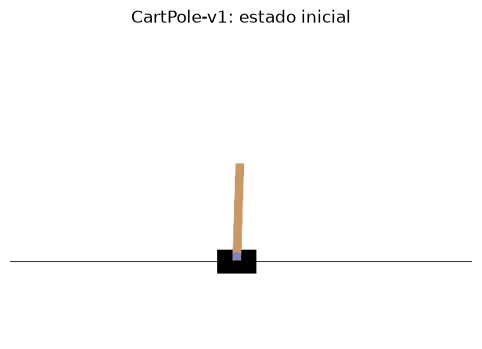

In [8]:
def plot_frame(frame, title=None, figsize=(6, 4)):
    """Exibe um frame RGB preservando a proporção original."""
    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(frame)          # sem extent: eixos em pixels, aspect correto
    ax.axis("off")
    if title:
        ax.set_title(title)
    plt.show()
    plt.close(fig)            # evita acúmulo de figuras

# Estado inicial: vetor contínuo [posição, velocidade, ângulo, vel. angular]
obs, info = env.reset()
print("Observação inicial:", np.round(obs, 4))
plot_frame(env.render(), title="CartPole-v1: estado inicial")

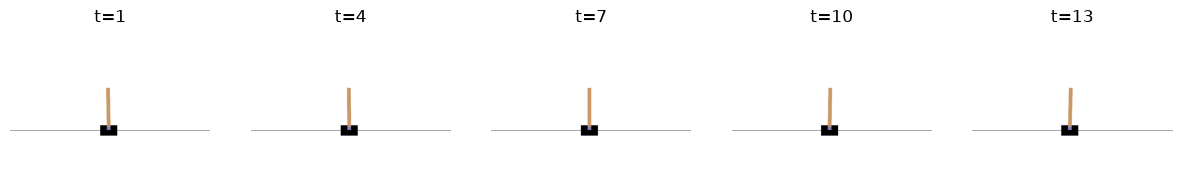

In [9]:
frames = []
obs, _ = env.reset()
for _ in range(15):
    obs, r, terminated, truncated, _ = env.step(env.action_space.sample())
    frames.append(env.render())
    if terminated or truncated:
        break

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, i in zip(axes, range(0, len(frames), max(1, len(frames)//5))):
    ax.imshow(frames[i]); ax.axis("off"); ax.set_title(f"t={i+1}")
plt.show(); plt.close(fig)

In [10]:
# CartPole-v1: 2 ações discretas; observação contínua [x, ẋ, θ, θ̇]; sem estado-objetivo.
# Recompensa: +1 por passo (inclusive o terminal). O sinal de falha é o fim do episódio.
obs, info = env.reset()   # célula autossuficiente

print(" t | a | ação                   | [x, ẋ, θ (rad), θ̇]       | reward | terminated | truncated")
for t in range(1, 21):
    action = env.action_space.sample()
    obs, reward, terminated, truncated, info = env.step(action)
    print(f"{t:2d} | {action} | {ACTION_NAMES[action]:<22} | {np.round(obs, 3)} | {reward:>6} | {str(terminated):>10} | {truncated}")
    if terminated or truncated:
        break

if terminated:
    u = env.unwrapped
    causa = "ângulo" if abs(obs[2]) > u.theta_threshold_radians else "posição"
    print(f"Falha por {causa} (limites: |θ|>{u.theta_threshold_radians:.3f} rad ou |x|>{u.x_threshold})")

 t | a | ação                   | [x, ẋ, θ (rad), θ̇]       | reward | terminated | truncated
 1 | 1 | push cart to the right | [ 0.015  0.227 -0.006 -0.322] |    1.0 |      False | False
 2 | 1 | push cart to the right | [ 0.02   0.423 -0.013 -0.616] |    1.0 |      False | False
 3 | 0 | push cart to the left  | [ 0.028  0.228 -0.025 -0.328] |    1.0 |      False | False
 4 | 1 | push cart to the right | [ 0.033  0.423 -0.032 -0.628] |    1.0 |      False | False
 5 | 0 | push cart to the left  | [ 0.041  0.229 -0.044 -0.346] |    1.0 |      False | False
 6 | 1 | push cart to the right | [ 0.046  0.424 -0.051 -0.652] |    1.0 |      False | False
 7 | 0 | push cart to the left  | [ 0.054  0.23  -0.064 -0.376] |    1.0 |      False | False
 8 | 0 | push cart to the left  | [ 0.059  0.036 -0.072 -0.104] |    1.0 |      False | False
 9 | 1 | push cart to the right | [ 0.059  0.232 -0.074 -0.418] |    1.0 |      False | False
10 | 1 | push cart to the right | [ 0.064  0.428 -0.082 -0.7

In [ ]:
from gym.wrappers.monitoring.video_recorder import VideoRecorder
before_training = "before_training.mp4"
video = VideoRecorder(env, before_training)

# returns an initial observation
state, info = env.reset()
env.render()
video.capture_frame()

for i in range(100):
    action = env.action_space.sample()

    state, reward, terminated, truncated, info = env.step(action)
    is_terminal = terminated or truncated

    env.render()
    video.capture_frame()

    if(is_terminal):
        print("step", i+1, ":", actions[action], ",", state, ",", reward, ",", terminated, ",", truncated, ",", info)
        break

video.close()

/usr/local/lib/python3.10/dist-packages/gym/wrappers/monitoring/video_recorder.py:101: DeprecationWarning: WARN: <class 'gym.wrappers.monitoring.video_recorder.VideoRecorder'> is marked as deprecated and will be removed in the future.
  logger.deprecation(


step 29 : push cart to the right , [-0.16985989 -0.6128782   0.22731633  1.1611004 ] , 1.0 , True , False , {}


In [11]:
def random_baseline(n_episodes=100, seed=SEED):
    e = gym.make("CartPole-v1")
    e.action_space.seed(seed)
    returns = []
    for ep in range(n_episodes):
        _, _ = e.reset(seed=seed + ep)
        done, G = False, 0.0
        while not done:
            _, r, terminated, truncated, _ = e.step(e.action_space.sample())
            G += r
            done = terminated or truncated
    returns.append(G)
    e.close()
    return np.mean(returns), np.std(returns)

print("Baseline aleatória (média, desvio):", random_baseline())

Baseline aleatória (média, desvio): (np.float64(29.0), np.float64(0.0))


In [12]:
from base64 import b64encode
from pathlib import Path
from gymnasium.wrappers import RecordVideo
from IPython.display import HTML, Video

def record_episode(policy_fn=None, folder="videos", prefix="before_training", seed=SEED):
    """Grava 1 episódio. policy_fn(obs) -> ação; se None, usa política aleatória."""
    rec_env = RecordVideo(gym.make("CartPole-v1", render_mode="rgb_array"),
                          video_folder=folder, name_prefix=prefix,
                          episode_trigger=lambda ep: True)
    obs, _ = rec_env.reset(seed=seed)
    done, G = False, 0.0
    while not done:
        action = rec_env.action_space.sample() if policy_fn is None else policy_fn(obs)
        obs, r, terminated, truncated, _ = rec_env.step(action)
        G += r
        done = terminated or truncated
    rec_env.close()   # finaliza o MP4
    return sorted(Path(folder).glob(f"{prefix}-episode-*.mp4"))[-1], G

def render_mp4(videopath, width=400):
    """Retorna HTML <video> com o MP4 embutido em base64."""
    path = Path(videopath)
    if not path.exists():
        raise FileNotFoundError(f"{path} não existe: o env foi fechado (env.close()) após a gravação?")
    b64 = b64encode(path.read_bytes()).decode()
    return (f'<video width="{width}" controls>'
            f'<source src="data:video/mp4;base64,{b64}" type="video/mp4"></video>')

before_training, G = record_episode()
print(f"Retorno do episódio gravado: {G}")
HTML(render_mp4(before_training))

/home/glauber/Projetos/others/notebooks/.venv/lib/python3.12/site-packages/gymnasium/wrappers/rendering.py:298: UserWarning: WARN: Overwriting existing videos at /home/glauber/Projetos/others/notebooks/videos folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


Retorno do episódio gravado: 35.0


##Experience Replay Buffer

We will use **Experience Replay** in order to store the agent's experiences in the form $(s_t, a_t, r_t, s_{t+1})$:
- **state** $s_t$ in which the agent was in
- **action** $a_t$ the agent selected in that state
- **reward** $r_t$ received for taking the action in the state
- **next state** $s_{t+1}$ that the agent arrived to after action

After collecting a number **N** of these tuples $(s_t, a_t, r_t, s_{t+1})$, we randomly pass the data to train network.

In [16]:
class ReplayBuffer:
    def __init__(self, max_length, obs_dim, seed=SEED):
        self.index, self.size, self.max_length = 0, 0, max_length
        self.rng = np.random.default_rng(seed)

        self.states      = np.zeros((max_length, obs_dim), dtype=np.float32)
        self.actions     = np.zeros(max_length, dtype=np.int64)    # exigido por gather/indexação
        self.rewards     = np.zeros(max_length, dtype=np.float32)
        self.next_states = np.zeros((max_length, obs_dim), dtype=np.float32)
        self.dones       = np.zeros(max_length, dtype=np.float32)  # 1.0 só quando terminated

    def __len__(self):
        return self.size

    def update(self, state, action, reward, next_state, terminated):
        # `terminated` (queda do poste/saída da pista), NÃO `terminated or truncated`
        self.states[self.index]      = state
        self.actions[self.index]     = action
        self.rewards[self.index]     = reward
        self.next_states[self.index] = next_state
        self.dones[self.index]       = float(terminated)

        self.index = (self.index + 1) % self.max_length
        self.size  = min(self.size + 1, self.max_length)

    def sample(self, batch_size):
        assert self.size >= batch_size, f"Warm-up incompleto: {self.size} < {batch_size}"
        idxs = self.rng.integers(0, self.size, size=batch_size)
        return (self.states[idxs], self.actions[idxs], self.rewards[idxs],
                self.next_states[idxs], self.dones[idxs])

In [18]:
buffer = ReplayBuffer(max_length=100_000, obs_dim=env.observation_space.shape[0])
# ...
next_obs, reward, terminated, truncated, _ = env.step(action)
buffer.update(obs, action, reward, next_obs, terminated)   # não passe `terminated or truncated`
done = terminated or truncated                              # só para controlar o laço do episódio

In [20]:
b = ReplayBuffer(3, 4)
for i in range(5):
    b.update(np.full(4, i), i % 2, 1.0, np.full(4, i + 1), terminated=False)

assert len(b) == 3
assert sorted(b.states[:, 0].tolist()) == [2, 3, 4]     # i=0 e i=1 foram sobrescritos
assert sorted(b.actions.tolist()) == [0, 0, 1]          # ações de i=2,3,4
assert b.index == 2                                     # 5 % 3: próxima escrita sobrescreve a posição 2
print("ReplayBuffer circular: OK")

ReplayBuffer circular: OK


## Linear Neural Network

A linear neural network to be used with Deep Q-learning algoritmh. It is useful for environments where we are not receiving an image as observation.

The input size of the network receives an input of the available environment states.

The output of the network is the Q-value for each available action. So the output size is the shape of the actions state.

The size of the hidden layers is arbitrary. So, it can be varied from one application to another and it is one of the parameters that are worth modifying to ensure greater efficiency in the network.

In [22]:
import torch
import torch.nn as nn

class OriginalNet(nn.Module):
    """Estrutura original: sem ativação após a 1ª camada."""
    def __init__(self, s, h, a):
        super().__init__()
        self.input_layer  = nn.Linear(s, h)
        self.hidden_layer = nn.Linear(h, h)
        self.output_layer = nn.Linear(h, a)
    def forward(self, x):
        x = self.input_layer(x)
        x = torch.relu(self.hidden_layer(x))
        return self.output_layer(x)

class FixedNet(OriginalNet):
    """Versão corrigida: ReLU após a 1ª camada."""
    def forward(self, x):
        x = torch.relu(self.input_layer(x))
        x = torch.relu(self.hidden_layer(x))
        return self.output_layer(x)

def collapsed_affine(net, s):
    """O que as duas primeiras camadas seriam se fossem uma só transformação afim."""
    W = net.hidden_layer.weight @ net.input_layer.weight
    b = net.hidden_layer.weight @ net.input_layer.bias + net.hidden_layer.bias
    return s @ W.T + b

torch.manual_seed(0)
s = torch.randn(5, 4)

orig, fixed = OriginalNet(4, 8, 2), FixedNet(4, 8, 2)

# Original: as duas camadas equivalem a uma só (colapso)
assert torch.allclose(orig.hidden_layer(orig.input_layer(s)), collapsed_affine(orig, s), atol=1e-5)

# Corrigida: não equivalem (a não linearidade quebra o colapso)
assert not torch.allclose(fixed.hidden_layer(torch.relu(fixed.input_layer(s))),
                          collapsed_affine(fixed, s), atol=1e-5)
print("OK: original colapsa; versão corrigida não")

OK: original colapsa; versão corrigida não


In [23]:
class LinearNetwork(nn.Module):
    """MLP para DQN: observação (state_size) -> Q-valores (action_size). Duas camadas ocultas com ReLU."""
    def __init__(self, state_size, hidden_size, action_size):
        super().__init__()
        self.input_layer  = nn.Linear(state_size, hidden_size)
        self.hidden_layer = nn.Linear(hidden_size, hidden_size)
        self.output_layer = nn.Linear(hidden_size, action_size)

    def forward(self, state):
        x = torch.relu(self.input_layer(state))    # correção: ativação após a 1ª camada
        x = torch.relu(self.hidden_layer(x))
        return self.output_layer(x)                # Q-valores, sem ativação


state_size  = env.observation_space.shape[0]       # 4
action_size = env.action_space.n                   # 2
policy_net = LinearNetwork(state_size, 128, action_size).to(device)

n_params = sum(p.numel() for p in policy_net.parameters())
print(f"input={state_size} | hidden=128 | output={action_size} | parâmetros={n_params}")  # 17.410

# Verificação de contrato
q = policy_net(torch.zeros(1, state_size, device=device))
assert q.shape == (1, action_size)

input=4 | hidden=128 | output=2 | parâmetros=17410


## Deep Q-learning Agent

In [24]:
import copy

class DeepQLearningAgent:
    def __init__(self, alpha_learning_rate, gamma_discount_factor, initial_epsilon,
                 epsilon_decay, final_epsilon, state_space, hidden_size, action_space,
                 device, model, optimizer, criterion, batch_size, max_memory,
                 tau=0.005, max_grad_norm=10.0, seed=SEED):
        # alpha_learning_rate e hidden_size mantidos só por compatibilidade: o lr está no otimizador
        self.gamma_discount_factor = gamma_discount_factor
        self.epsilon = initial_epsilon
        self.epsilon_decay = epsilon_decay
        self.final_epsilon = final_epsilon
        self.state_space = state_space
        self.action_space = action_space
        self.device = device
        self.model = model
        self.optimizer = optimizer
        self.criterion = criterion          # recomendado: nn.SmoothL1Loss()
        self.batch_size = batch_size
        self.tau = tau
        self.max_grad_norm = max_grad_norm
        self.training_error = []

        # Rede-alvo: cópia congelada, atualizada suavemente (Polyak)
        self.target_model = copy.deepcopy(model).to(device).eval()
        for p in self.target_model.parameters():
            p.requires_grad_(False)

        self.rng = np.random.default_rng(seed)
        self.memory = ReplayBuffer(max_memory, state_space.shape[0], seed=seed)

    @torch.no_grad()
    def eval_state(self, state):
        s = torch.as_tensor(state, dtype=torch.float32, device=self.device).unsqueeze(0)
        return self.model(s).argmax(dim=1).item()

    def choose_action(self, state):
        if self.rng.uniform() < self.epsilon:
            return self.action_space.sample()
        return self.eval_state(state)

    def remember(self, state, action, reward, next_state, terminated):
        self.memory.update(state, action, reward, next_state, terminated)  # só terminated

    @torch.no_grad()
    def _soft_update(self):
        for tp, p in zip(self.target_model.parameters(), self.model.parameters()):
            tp.mul_(1.0 - self.tau).add_(p, alpha=self.tau)

    def update(self):
        if len(self.memory) < self.batch_size * 10:   # warm-up
            return None
        s, a, r, s2, d = self.memory.sample(self.batch_size)
        s  = torch.as_tensor(s,  device=self.device)
        a  = torch.as_tensor(a,  device=self.device).long().unsqueeze(-1)
        r  = torch.as_tensor(r,  device=self.device).unsqueeze(-1)
        s2 = torch.as_tensor(s2, device=self.device)
        d  = torch.as_tensor(d,  device=self.device).float().unsqueeze(-1)

        q_pred = self.model(s).gather(1, a)
        with torch.no_grad():
            q_next = self.target_model(s2).max(dim=1, keepdim=True)[0]   # rede-alvo
            target = r + (1.0 - d) * self.gamma_discount_factor * q_next

        loss = self.criterion(q_pred, target)
        self.optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(self.model.parameters(), self.max_grad_norm)
        self.optimizer.step()
        self._soft_update()

        value = loss.item()
        self.training_error.append(value)
        return value

    def decay_epsilon(self):
        self.epsilon = max(self.final_epsilon, self.epsilon - self.epsilon_decay)

## Setting hyperparameters and initializing an agent

In [26]:
agent = DeepQLearningAgent(1e-3, 0.99, 1.0, 1e-3, 0.05, env.observation_space, 128,
                           env.action_space, device, policy_net,
                           optim.Adam(policy_net.parameters(), lr=1e-3), nn.SmoothL1Loss(), 64, 50_000)
assert all(torch.equal(a, b) for a, b in zip(agent.model.parameters(), agent.target_model.parameters()))
assert not any(p.requires_grad for p in agent.target_model.parameters())
agent.decay_epsilon(); assert abs(agent.epsilon - 0.999) < 1e-9   # usa self.epsilon_decay

In [27]:
for _ in range(700):   # acima do warm-up (64 * 10 = 640)
    agent.remember(np.random.randn(4).astype(np.float32), np.random.randint(2), 1.0,
                   np.random.randn(4).astype(np.float32), False)

w_online0 = [p.clone() for p in agent.model.parameters()]
w_target0 = [p.clone() for p in agent.target_model.parameters()]
loss = agent.update()

assert loss is not None                                                                  # saiu do warm-up
assert any(not torch.equal(a, b) for a, b in zip(w_online0, agent.model.parameters()))   # online mudou
assert any(not torch.equal(a, b) for a, b in zip(w_target0, agent.target_model.parameters()))  # alvo mudou, via soft update
assert all(p.grad is None for p in agent.target_model.parameters())                      # alvo sem gradiente
print("Update OK | loss =", round(loss, 4))

Update OK | loss = 0.5649


### Test accurracy

In [29]:
import imageio.v2 as imageio
from pathlib import Path

def record_trained_video(agent, video_file, num_steps=500, seed=SEED):
    """Grava 1 episódio com política gulosa em ambiente dedicado. Retorna (retorno, passos)."""
    Path(video_file).parent.mkdir(parents=True, exist_ok=True)
    rec_env = gym.make("CartPole-v1", render_mode="rgb_array")
    try:
        obs, _ = rec_env.reset(seed=seed)
        frames, G, t = [rec_env.render()], 0.0, 0
        for t in range(1, num_steps + 1):
            obs, r, terminated, truncated, _ = rec_env.step(agent.eval_state(obs))
            G += r
            frames.append(rec_env.render())
            if terminated or truncated:
                break
        fps = rec_env.metadata.get("render_fps", 50)
    finally:
        rec_env.close()
    imageio.mimsave(video_file, frames, fps=fps)
    print(f"Episódio: {t} passos | retorno {G} | vídeo: {video_file}")
    return G, t


def evaluate(agent, n_episodes=20, seed=SEED):
    """Retorno médio e desvio em N episódios com seeds fixas e política gulosa."""
    e = gym.make("CartPole-v1")
    returns = []
    for ep in range(n_episodes):
        obs, _ = e.reset(seed=seed + ep)
        done, G = False, 0.0
        while not done:
            obs, r, terminated, truncated, _ = e.step(agent.eval_state(obs))
            G += r
            done = terminated or truncated
        returns.append(G)          # dentro do laço de episódios
    e.close()
    return np.mean(returns), np.std(returns)

## Playing and Training

In [30]:
from tqdm import tqdm

# --- Hiperparâmetros (explícitos) ---
nb_max_episodes = 500
test_freq       = 10
eval_episodes   = 25
final_epsilon   = 0.05
epsilon_decay   = (1.0 - final_epsilon) / (0.5 * nb_max_episodes)   # ε no piso na metade do treino

# --- Estado limpo: reinstancia rede e agente ---
torch.manual_seed(SEED)
env.action_space.seed(SEED)
policy_net = LinearNetwork(state_size, 128, action_size).to(device)
agent = DeepQLearningAgent(1e-3, 0.99, 1.0, epsilon_decay, final_epsilon, env.observation_space, 128,
                           env.action_space, device, policy_net,
                           optim.Adam(policy_net.parameters(), lr=1e-3), nn.SmoothL1Loss(), 64, 50_000)

train_returns, eval_returns, recent = [], [], []
total_steps, best_eval = 0, -np.inf

for episode in tqdm(range(nb_max_episodes)):
    state, _ = env.reset(seed=SEED if episode == 0 else None)
    done, total_reward = False, 0.0

    while not done:
        action = agent.choose_action(state)
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated                                  # só controla o laço

        agent.remember(state, action, reward, next_state, terminated)  # só terminated entra no alvo
        agent.update()

        state = next_state
        total_steps += 1
        total_reward += reward

    agent.decay_epsilon()
    train_returns.append(total_reward)
    recent.append(total_reward)

    if (episode + 1) % test_freq == 0:
        eval_mean, eval_std = evaluate(agent, eval_episodes)            # ambiente dedicado, política gulosa
        eval_returns.append(eval_mean)
        if eval_mean > best_eval:
            best_eval = eval_mean
            torch.save(agent.model.state_dict(), "best_policy.pt")
        tqdm.write(f"ep {episode+1} | passos {total_steps} | treino {np.mean(recent):.1f} | "
                   f"teste {eval_mean:.1f}±{eval_std:.1f} | ε {agent.epsilon:.3f}")
        recent.clear()

# --- Avaliação final com seeds diferentes das usadas para escolher o checkpoint ---
agent.model.load_state_dict(torch.load("best_policy.pt", map_location=device))
mean_f, std_f = evaluate(agent, 100, seed=10_000)
print(f"Final (100 episódios, seeds novas): {mean_f:.1f} ± {std_f:.1f} | limiar de 'resolvido': 475")

record_trained_video(agent, "videos/after_training.mp4", env.spec.max_episode_steps)
env.close()

  5%|▍         | 23/500 [00:00<00:04, 102.70it/s]

ep 10 | passos 318 | treino 31.8 | teste 13.2±4.7 | ε 0.962
ep 20 | passos 545 | treino 22.7 | teste 13.2±4.7 | ε 0.924


  7%|▋         | 34/500 [00:00<00:13, 35.47it/s] 

ep 30 | passos 773 | treino 22.8 | teste 9.8±1.2 | ε 0.886


  8%|▊         | 41/500 [00:01<00:17, 26.30it/s]

...

ep 490 | passos 43069 | treino 328.1 | teste 189.1±123.2 | ε 0.050


100%|██████████| 500/500 [02:35<00:00,  3.21it/s]


ep 500 | passos 45927 | treino 285.8 | teste 500.0±0.0 | ε 0.050
Final (100 episódios, seeds novas): 500.0 ± 0.0 | limiar de 'resolvido': 475


IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (600, 400) to (608, 400) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


Episódio: 500 passos | retorno 500.0 | vídeo: videos/after_training.mp4


In [31]:
from pathlib import Path
from IPython.display import HTML, display

after_training = "videos/after_training.mp4"
# (na Parte 11: G, t = record_trained_video(agent, after_training, 500, seed=10_000))

assert Path(after_training).exists(), "Vídeo não encontrado: a gravação rodou e o env foi fechado?"
print(f"Arquivo: {Path(after_training).stat().st_size/1e3:.0f} KB")

def side_by_side(paths_titles, width=380):
    cells = "".join(
        f"<div><b>{title}</b><br>{render_mp4(p, width)}</div>" for p, title in paths_titles)
    return f'<div style="display:flex;gap:16px">{cells}</div>'

display(HTML(side_by_side([(before_training, "Antes do treino (aleatória)"),
                           (after_training,  "Depois do treino (gulosa)")])))

Arquivo: 43 KB


### Metrics

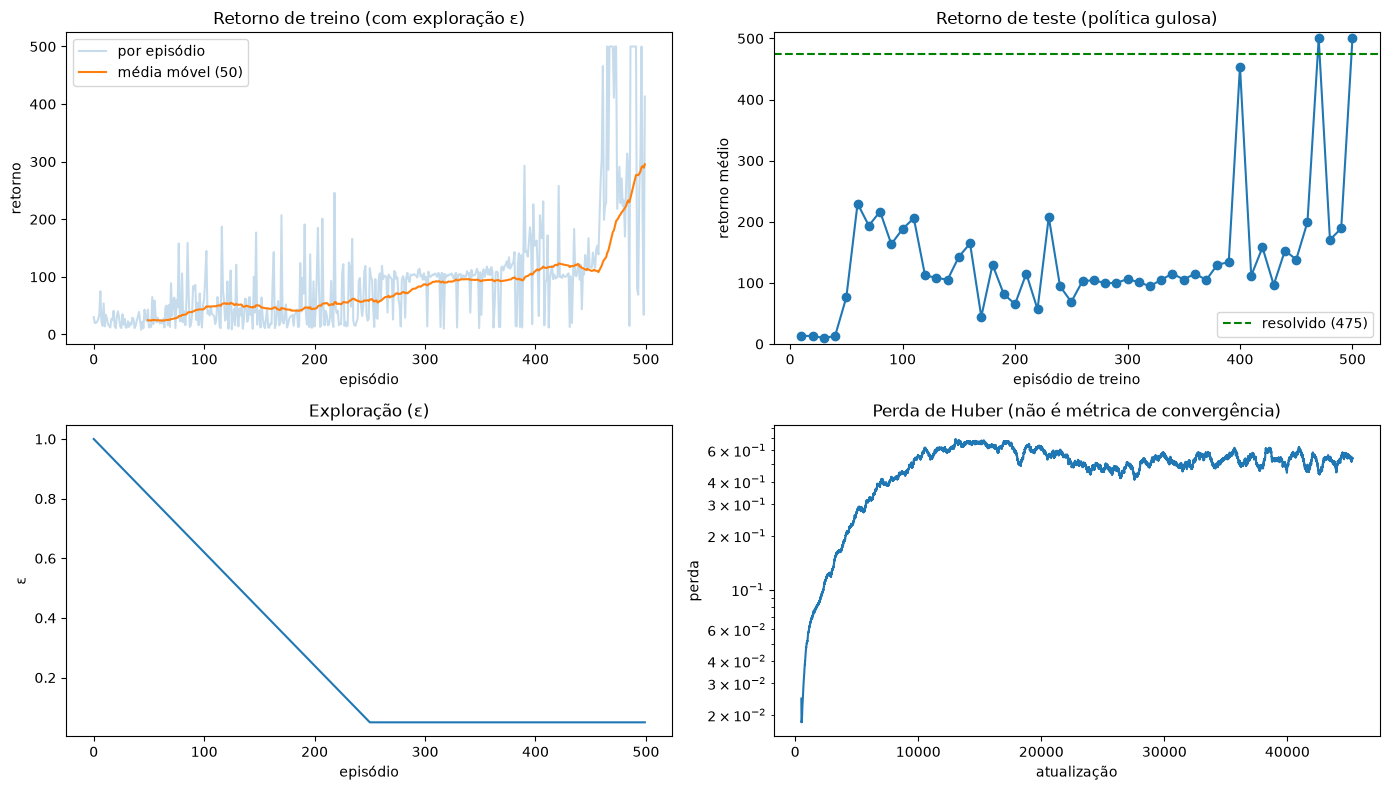

In [32]:
def moving_average(x, w):
    """Média móvel só com janelas completas ('valid'): sem viés nas bordas."""
    x = np.asarray(x, dtype=float)
    w = min(w, len(x))
    if w == 0:
        return np.array([]), np.array([])
    return np.arange(w - 1, len(x)), np.convolve(x, np.ones(w) / w, mode="valid")

def plot_learning_curves(train_returns, eval_returns, losses, test_freq,
                         epsilon_decay, final_epsilon, window=50, threshold=475):
    fig, axs = plt.subplots(2, 2, figsize=(14, 8))

    ax = axs[0, 0]
    ax.plot(train_returns, alpha=0.25, label="por episódio")
    ax.plot(*moving_average(train_returns, window), label=f"média móvel ({window})")
    ax.set(title="Retorno de treino (com exploração ε)", xlabel="episódio", ylabel="retorno")
    ax.legend()

    ax = axs[0, 1]
    ax.plot((np.arange(len(eval_returns)) + 1) * test_freq, eval_returns, marker="o")
    ax.axhline(threshold, ls="--", c="g", label=f"resolvido ({threshold})")
    ax.set(title="Retorno de teste (política gulosa)", xlabel="episódio de treino",
           ylabel="retorno médio", ylim=(0, 510))
    ax.legend()

    ax = axs[1, 0]   # cronograma de ε, assumindo ε inicial 1.0 e decaimento por episódio (Parte 11)
    ax.plot(np.maximum(final_epsilon, 1.0 - epsilon_decay * np.arange(len(train_returns))))
    ax.set(title="Exploração (ε)", xlabel="episódio", ylabel="ε")

    ax = axs[1, 1]
    ax.plot(*moving_average(losses, 500))
    ax.set(title="Perda de Huber (não é métrica de convergência)", xlabel="atualização",
           ylabel="perda", yscale="log")

    plt.tight_layout(); plt.show(); plt.close(fig)

plot_learning_curves(train_returns, eval_returns, agent.training_error,
                     test_freq, epsilon_decay, final_epsilon)

In [33]:
x = np.full(300, 500.0)
bad = np.convolve(x, np.ones(100), mode="same") / 100
_, good = moving_average(x, 100)
assert bad[0] < 300 and bad[-1] < 300        # 'same': bordas ≈ metade do valor real
assert np.allclose(good, 500)                # 'valid': constante, como deveria

In [34]:
with torch.no_grad():
    sample = agent.memory.states[:min(len(agent.memory), 1000)]
    q_mean = agent.model(torch.as_tensor(sample, device=device)).max(1)[0].mean().item()